# 05 - Interpretation and evaluation (KDD stage 5) - real data
What the models learned, how well they work, where they fail, and what the results can and cannot be used for.

**Reminder of the task:** forecast whether *tomorrow* brings >= 10 mm of rain at Durban or Mbombela, using weather up to
today. This is a rainfall-hazard proxy built from two weather files; it is **not** a flood-prediction result.

In [1]:
import sys
from pathlib import Path


def _find_helpers():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "notebooks" / "real_data"):
            if (cand / "weather_data.py").is_file():
                return cand
    raise SystemExit("weather_data.py not found. Open this notebook from inside the repository.")


sys.path.insert(0, str(_find_helpers()))

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

import weather_data as wd

ROOT = wd.find_root()
OUT = wd.out_dir(ROOT)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
LABEL = {rid: s["label"] for rid, s in wd.STATIONS.items()}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = {"persistence": "#9aa5b1", "logistic_regression": "#2a6fbb", "random_forest": "#2a9d8f", "gradient_boosting": "#d9822b"}
NAMES = list(PALETTE)

m = json.loads((OUT / "metrics.json").read_text())
oof = pd.read_csv(OUT / "predictions_walk_forward.csv", parse_dates=["date"])
test_pred = pd.read_csv(OUT / "predictions_test.csv", parse_dates=["date"])
bundle = joblib.load(OUT / "rain_models_holdout.joblib")
feat = pd.read_csv(OUT / "weather_features.csv", parse_dates=["date"])
FEATURES = bundle["features"]
print("target:", m["target"])

target: rain on day t+1 >= 10.0 mm (rainfall proxy, NOT recorded floods)


## 1. Results at a glance

In [2]:
hold = pd.DataFrame(m["holdout_test"]).T[["accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]].astype(float)
wf = pd.DataFrame(m["walk_forward"]).T[["roc_auc_pooled", "avg_precision_pooled", "roc_auc_fold_min", "roc_auc_fold_max"]]
base_rate = oof["y"].mean()
print(f"hold-out test: {m['positives']['test']} heavy-rain days | walk-forward pooled: {m['positives']['walk_forward_pooled']} heavy-rain days "
      f"(base rate {base_rate:.1%}, so a no-skill average precision is about {base_rate:.2f})")
hold.round(3)

hold-out test: 8 heavy-rain days | walk-forward pooled: 46 heavy-rain days (base rate 8.9%, so a no-skill average precision is about 0.09)


,accuracy,precision,recall,f1,roc_auc,avg_precision
always_no,0.949,0.000,0.000,0.000,0.500,0.051
persistence,0.942,0.444,0.500,0.471,0.802,0.494
logistic_regression,0.923,0.167,0.125,0.143,0.699,0.137
random_forest,0.942,0.000,0.000,0.000,0.704,0.143
gradient_boosting,0.929,0.200,0.125,0.154,0.718,0.167


In [3]:
wf.round(3)

,roc_auc_pooled,avg_precision_pooled,roc_auc_fold_min,roc_auc_fold_max
persistence,0.753,0.273,0.649,0.831
logistic_regression,0.599,0.147,0.450,0.809
random_forest,0.674,0.151,0.458,0.775
gradient_boosting,0.669,0.143,0.496,0.760


## 2. ROC and precision-recall curves (walk-forward, out-of-fold)
Every point below was predicted by a model that had never seen that day or anything later - the closest this small
dataset gets to a real forecasting test.

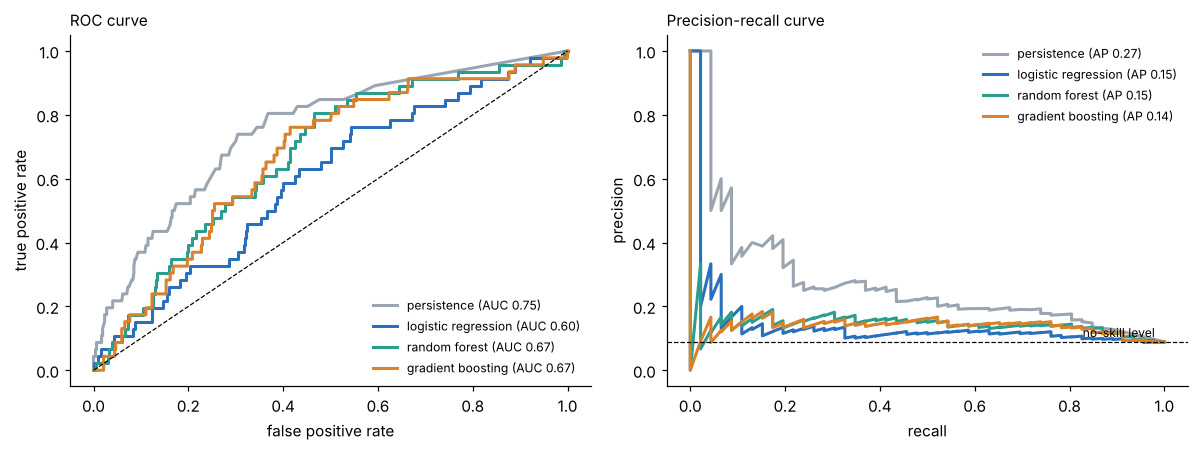

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
y = oof["y"].to_numpy()
for name in NAMES:
    fpr, tpr, _ = roc_curve(y, oof[name])
    axes[0].plot(fpr, tpr, color=PALETTE[name], lw=2, label=f"{name.replace('_', ' ')} (AUC {m['walk_forward'][name]['roc_auc_pooled']:.2f})")
    prec, rec, _ = precision_recall_curve(y, oof[name])
    axes[1].plot(rec, prec, color=PALETTE[name], lw=2, label=f"{name.replace('_', ' ')} (AP {m['walk_forward'][name]['avg_precision_pooled']:.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curve", loc="left", fontsize=10)
axes[1].axhline(base_rate, color="k", ls="--", lw=0.8)
axes[1].text(0.98, base_rate + 0.015, "no-skill level", fontsize=8, ha="right")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve", loc="left", fontsize=10)
for ax in axes:
    ax.legend(frameon=False, fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout()
fig.savefig(FIG / "05_roc_pr_walk_forward.png", dpi=130)
plt.show()

## 3. What does a warning look like? Confusion matrices on the hold-out test split

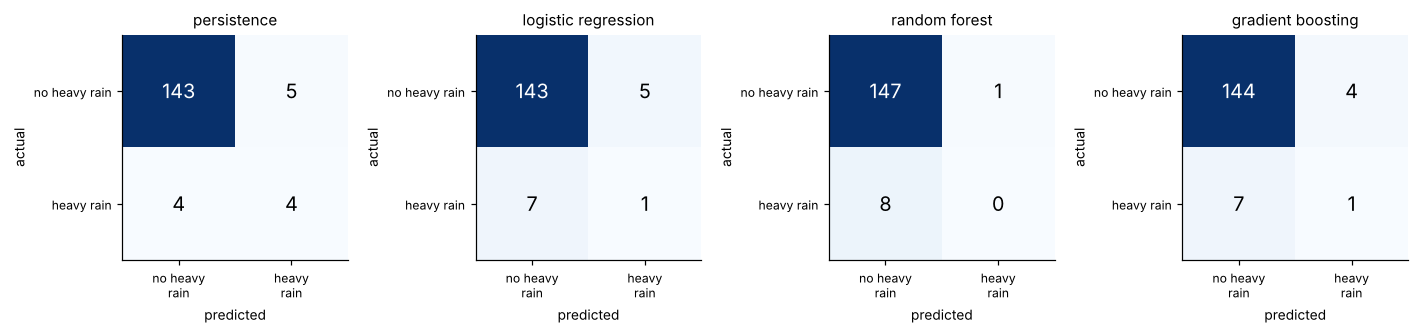

In [5]:
show = ["persistence", "logistic_regression", "random_forest", "gradient_boosting"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, name in zip(axes, show):
    cm = np.array(m["holdout_test"][name]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["no heavy\nrain", "heavy\nrain"], fontsize=8)
    ax.set_yticks([0, 1], ["no heavy rain", "heavy rain"], fontsize=8)
    ax.set_xlabel("predicted", fontsize=9)
    ax.set_ylabel("actual", fontsize=9)
    ax.set_title(name.replace("_", " "), fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "05_confusion_matrices.png", dpi=130)
plt.show()

Missed heavy-rain days (bottom-left) are the costly error for an early-warning system; false alarms (top-right) cost
trust. The threshold was chosen on the validation split to balance the two via F1; an operator could instead
pick a lower threshold to favour recall.

## 4. What drives the forecast? (permutation importance)
Shuffle one feature at a time on validation+test days and measure how much the gradient-boosting model's average
precision drops. Bigger drop = the model leans on that feature more.

,feature,drop_in_avg_precision,std
0,rainfall_mm,0.0917,0.0245
11,dpressure_1d,0.0367,0.0201
9,pressure_hpa,0.0335,0.0303
10,wind_ms,0.0071,0.0282
3,rain_lag3,0.0007,0.0021
13,doy_sin,0.0002,0.0017


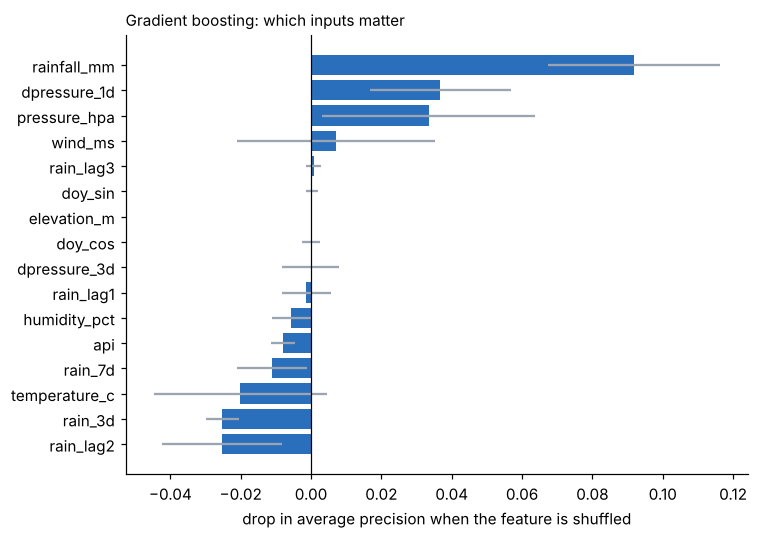

In [6]:
gb = bundle["models"]["gradient_boosting"]
vt = feat[feat["split"].isin(["val", "test"])]
imp = permutation_importance(gb, vt[FEATURES].to_numpy(), vt["y"].to_numpy(), scoring="average_precision",
                             n_repeats=30, random_state=wd.SEED)
imp_df = pd.DataFrame({"feature": FEATURES, "drop_in_avg_precision": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("drop_in_avg_precision", ascending=True)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp_df["feature"], imp_df["drop_in_avg_precision"], xerr=imp_df["std"], color="#2a6fbb", ecolor="#9aa5b1")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("drop in average precision when the feature is shuffled")
ax.set_title("Gradient boosting: which inputs matter", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "05_permutation_importance.png", dpi=130)
plt.show()
imp_df.sort_values("drop_in_avg_precision", ascending=False).head(6).round(4)

Features with a bar near zero (or error bars crossing zero) add nothing the model can reliably use on this data.
With only 55 positive days in total, importances are indicative, not precise.

## 5. Case study: the April and May 2022 rain events at Durban
Out-of-fold probabilities (made one day ahead) around the wettest days. The line is the model's estimate, made
at the end of each day, that **the next day** will see >= 10 mm; bars show the rain that actually fell.

best walk-forward model by pooled ROC-AUC: random_forest


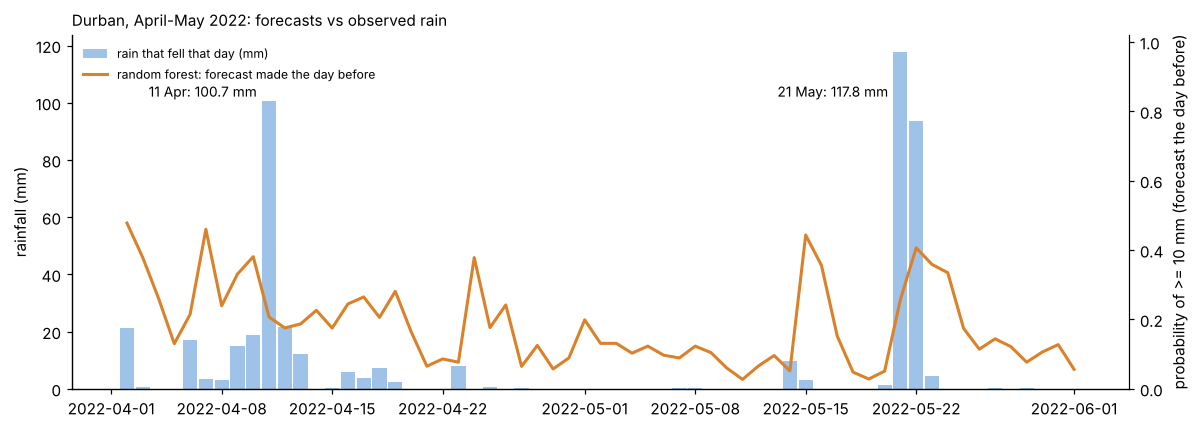

In [7]:
d = oof[oof["region_id"] == "KZN-ETHEKWINI"].sort_values("date")
d = d[(d["date"] >= "2022-04-01") & (d["date"] <= "2022-05-31")]
best = max(NAMES[1:], key=lambda n: m["walk_forward"][n]["roc_auc_pooled"])
print("best walk-forward model by pooled ROC-AUC:", best)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(d["date"] + pd.Timedelta(days=1), d["target_rain_next_mm"], width=0.9, color="#9fc3e8", label="rain that fell that day (mm)")
ax.set_ylabel("rainfall (mm)")
ax2 = ax.twinx()
ax2.plot(d["date"] + pd.Timedelta(days=1), d[best], color="#d9822b", lw=2, label=f"{best.replace('_', ' ')}: forecast made the day before")
ax2.set_ylim(0, 1.02)
ax2.set_ylabel("probability of >= 10 mm (forecast the day before)")
ax2.spines["right"].set_visible(True)
for day, text in (("2022-04-11", "11 Apr: 100.7 mm"), ("2022-05-21", "21 May: 117.8 mm")):
    ax.annotate(text, (pd.Timestamp(day), 100), xytext=(-8, 4), textcoords="offset points", ha="right", fontsize=9)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left")
ax.set_title("Durban, April-May 2022: forecasts vs observed rain", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "05_case_study_durban.png", dpi=130)
plt.show()

In [8]:
events = []
for day in ("2022-04-11", "2022-05-21", "2022-05-22"):
    row = oof[(oof["region_id"] == "KZN-ETHEKWINI") & (oof["date"] == pd.Timestamp(day) - pd.Timedelta(days=1))]
    if len(row):
        r = row.iloc[0]
        events.append({"event_day": day, "rain_that_day_mm": r["target_rain_next_mm"],
                       **{f"p_{n}": round(float(r[n]), 2) for n in NAMES[1:]}})
pd.DataFrame(events)

,event_day,rain_that_day_mm,p_logistic_regression,p_random_forest,p_gradient_boosting
0,2022-04-11,100.7,0.11,0.21,0.02
1,2022-05-21,117.8,0.32,0.26,0.04
2,2022-05-22,93.7,1.00,0.41,0.33


The table gives each model's forecast issued the evening before the wettest days. Compare it with the
7-9% base rate: probabilities far above it mean the model saw it coming; probabilities near it mean the event
arrived without a signal in the previous days' weather.

## 6. Do the machine-learning models beat the simple rule?
The question that matters is whether logistic regression, random forest or gradient boosting add anything over
the persistence rule ("heavy rain today -> heavy rain tomorrow"). The cell below answers it from the saved metrics.

In [9]:
wf_m, h_m = m["walk_forward"], m["holdout_test"]
best_ml = max(NAMES[1:], key=lambda n: wf_m[n]["roc_auc_pooled"])
rows = []
for label, ml_val, base_val in (
    ("walk-forward pooled ROC-AUC", wf_m[best_ml]["roc_auc_pooled"], wf_m["persistence"]["roc_auc_pooled"]),
    ("walk-forward pooled avg precision", wf_m[best_ml]["avg_precision_pooled"], wf_m["persistence"]["avg_precision_pooled"]),
    ("hold-out test ROC-AUC", h_m[best_ml]["roc_auc"], h_m["persistence"]["roc_auc"]),
    ("hold-out test F1", h_m[best_ml]["f1"], h_m["persistence"]["f1"]),
):
    rows.append({"metric": label, f"best learned model ({best_ml})": round(ml_val, 3), "persistence": round(base_val, 3),
                 "learned model wins?": "yes" if ml_val > base_val else "no"})
verdict = pd.DataFrame(rows).set_index("metric")
wins = int((verdict["learned model wins?"] == "yes").sum())
print(f"The best learned model beats persistence on {wins} of {len(verdict)} measures.")
verdict

The best learned model beats persistence on 0 of 4 measures.


,best learned model (random_forest),persistence,learned model wins?
metric,,,
walk-forward pooled ROC-AUC,0.674,0.753,no
walk-forward pooled avg precision,0.151,0.273,no
hold-out test ROC-AUC,0.704,0.802,no
hold-out test F1,0.000,0.471,no


## 7. Honest conclusions
**What the evidence supports**
- On this dataset the simple persistence rule is a strong baseline: in the run recorded above it matches or beats every
  learned model on the pooled walk-forward and the hold-out measures (see the table in section 6). With
  about a year of data from two sites, the extra capacity of the machine-learning models is not paying for itself yet.
- The models do rank days better than chance on most folds (AUC above 0.5), but fold-to-fold swings are large
  (notebook 04, walk-forward figure), and the early folds, with the least training data, are close to chance.
- The importance plot shows the forecast leans mostly on today's rainfall, which is exactly what persistence uses.
- The wettest Durban days (11 April and 21 May 2022) were **not** anticipated by the learned models: the forecasts
  issued the evening before were low (see the case-study table). A rule or model built only on daily
  weather from the day before cannot see a storm that develops overnight.

**What it does not support**
- **Not flood prediction.** The target is next-day rainfall >= 10 mm. No flood records, river levels or satellite
  data were available in these files.
- **Small sample.** Two locations, 12 months, 55 heavy-rain days in total (8 in the test split). Intervals are wide
  (notebook 04, section 3) and a different year could rank the models differently.
- **Reanalysis, not gauges.** Open-Meteo reanalysis smooths local extremes; SAWS station data would differ.
- **Station-specific.** Elevation is constant per station, so the model cannot separate "elevation effect" from
  "which station"; do not extrapolate to other places.
- These numbers must **not** be used as evidence for the project's flood-accuracy objective.

**Next steps toward the real objective**
1. Add event labels (EM-DAT, DesInventar, NDMC reports) and river-level data - see `docs/REAL_DATA_GUIDE.md`.
2. Extend the record to several years and more stations/districts so the test split has dozens of events.
3. Re-run notebooks 02-05 unchanged apart from the target definition in notebook 03.